## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [1]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Roshan Mahesh

**Date:** 10/15/2026

Unique tokens: 48691
Share appearing exactly once: 0.604


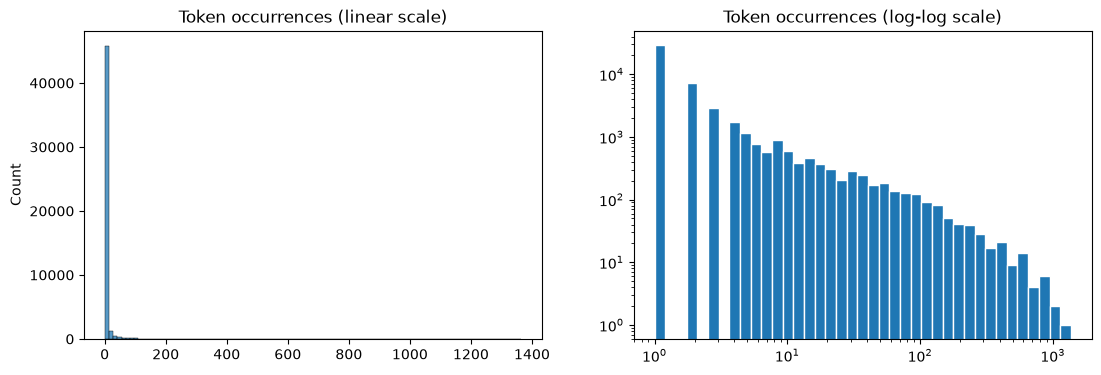

Train R^2: 0.766
Test R^2: 0.6702
                  token      coef  abs_coef
1504  background-image: -1.201203  1.201203
740           localized  0.815112  0.815112
906               aging  0.735023  0.735023
2362            thermal  0.590412  0.590412
1406         helvetica,  0.587472  0.587472
835        intervention -0.580474  0.580474
1302           erectile  0.575784  0.575784
1511            burning -0.569225  0.569225
1839              form.  0.560255  0.560255
2559            april's -0.525984  0.525984
818                cnet -0.495563  0.495563
2532             xanaax  0.490234  0.490234
2657              zdnet -0.487835  0.487835
1256             arial, -0.483577  0.483577
2365                rcs  0.464646  0.464646


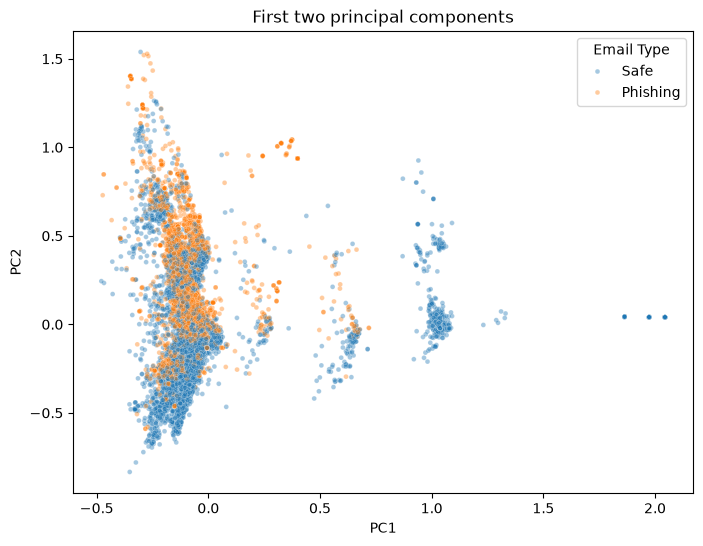

Train R^2: 0.7651
Test R^2: 0.6718


In [2]:
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
#converts the token frequency list into a Series of token counts
counts = pd.Series(dict(token_freq))
#prints summary stats on how often tokens appear
print('Unique tokens:', len(counts))
print('Share appearing exactly once:', round((counts == 1).mean(), 3))
#plots histograms of token occurrences on a linear scale and a log-log scale
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(counts, bins=100, ax=axes[0])
axes[0].set_title('Token occurrences (linear scale)')
log_bins = np.logspace(0, np.log10(counts.max()), 40)
axes[1].hist(counts, bins=log_bins, edgecolor='white')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_title('Token occurrences (log-log scale)')
plt.show()
#Answer: The distribution is extremely right-skewed, with about 60% of tokens appearing only once while a few words like "new" and "enron" appear over 900 times, forming a nearly straight line on a log-log plot (Zipf's law).
#Q2
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

#loads the email data and separates the outcome from the token features
df = pd.read_parquet('data/Phishing_clean.parquet')
y = df['Email Type']
X = df.drop(columns='Email Type')

#performs an 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=125)
#fits a linear regression on the tokens and prints train and test R^2
lm = LinearRegression().fit(X_train, y_train)
print('Train R^2:', round(lm.score(X_train, y_train), 4))
print('Test R^2:', round(lm.score(X_test, y_test), 4))
#ranks tokens by the absolute value of their coefficients
coefs = pd.DataFrame({'token': X.columns, 'coef': lm.coef_})
coefs['abs_coef'] = coefs['coef'].abs()
print(coefs.sort_values('abs_coef', ascending=False).head(15))
#Answer: The test R^2 is about 0.67 and the train R^2 is about 0.77, and the most influential words are "background-image:", "localized", "aging", "thermal", "helvetica,", "intervention", and "erectile".

#Q3
from sklearn.decomposition import PCA

#runs PCA with two components on the token matrix
pca2 = PCA(n_components=2)
Z2 = pca2.fit_transform(X)

#builds a dataframe of the two components labeled by email type
pc_df = pd.DataFrame(Z2, columns=['PC1', 'PC2'])
pc_df['Email Type'] = y.map({0: 'Safe', 1: 'Phishing'}).values

#plots PC1 vs PC2 colored by whether the email is phishing
plt.figure(figsize=(8, 6))
sns.scatterplot(data=pc_df, x='PC1', y='PC2', hue='Email Type', alpha=0.4, s=12)
plt.title('First two principal components')
plt.show()

#Answer: Phishing emails mostly sit higher on PC2 and safe emails spread out more along PC1, but there's a lot of overlap in the middle.

#Q4
#fits PCA with 2,610 components on the training set and transforms both sets
pca = PCA(n_components=2610)
Z_train = pca.fit_transform(X_train)
Z_test = pca.transform(X_test)

#fits a linear regression on the principal components and prints train and test R^2
lm_pc = LinearRegression().fit(Z_train, y_train)
print('Train R^2:', round(lm_pc.score(Z_train, y_train), 4))
print('Test R^2:', round(lm_pc.score(Z_test, y_test), 4))

#Answer: Train R^2 is about 0.765 and test is about 0.672, so it does basically the same as the regular regression.

#Q5
#Answer: The components aren't correlated with each other, so the regression is more stable and you can drop the noisy ones to avoid overfitting.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 838cc7d3eb10d4dfe6865c29a13d8f1d7b1ca409
- **AI tool and model used:** ChatGPT Sol 5.6

### *Prompts used

1. How can I improve my code to ensure that I answered the questions as efficent as possible?

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Simplify Q1 token frequency calculations by removing unnecessary data conversions and using the existing token counts directly.
2. Use logarithmic bins in the Q1 histogram to better display the distribution of token frequencies.
3. Improve Q1 graph labels and titles to make the visualizations easier to interpret.
4. Add stratification to the Q2 train-test split to preserve the proportion of phishing and safe emails.
5. Separate the largest positive and negative regression coefficients in Q2 to better identify which features influence predictions.
6. Add explained variance ratios in Q3 to show how much variation the first two principal components capture.
7. Reduce overlapping points in the Q3 scatter plot by adjusting marker size and transparency.
8. Add validation in Q4 to ensure the requested 2,610 principal components do not exceed the allowable number.
9. Verify that PCA in Q4 is fitted only on training data to prevent data leakage.
10. Improve the Q5 comparison by directly examining the training and test R² scores from Q2 and Q4, explaining whether PCA reduced overfitting.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Removes unnecessary conversions and simplifies the code while preserving the same token counts. Verify by comparing the original and revised results. |
| 2 | Modify | Use logarithmic bins only if they make the distribution easier to interpret. Verify by comparing both histograms. |
| 3 | Accept | Clearer labels and titles improve readability without changing the results. Verify that each label accurately describes the data. |
| 4 | Accept | Stratification preserves the proportion of phishing and safe emails in both datasets. Verify by comparing class distributions. |
| 5 | Accept | Separating positive and negative coefficients makes their effects easier to interpret. Verify that coefficients are correctly sorted and matched to features. |
| 6 | Accept | Explained variance ratios show how much variation the first two components capture. Verify using PCA's explained_variance_ratio_ attribute. |
| 7 | Accept | Smaller markers and transparency reduce overlapping points. Verify visually that both classes remain distinguishable. |
| 8 | Accept | Validating the component count prevents PCA errors. Verify that 2,610 does not exceed the allowable number of components. |
| 9 | Accept | Fitting PCA only on training data prevents data leakage. Verify that the test data is transformed using the fitted training PCA model. |
| 10 | Accept | Comparing training and test R² scores helps determine whether PCA reduces overfitting. Verify using the actual scores from both models. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

Unique tokens: 48691
Share appearing exactly once: 0.604


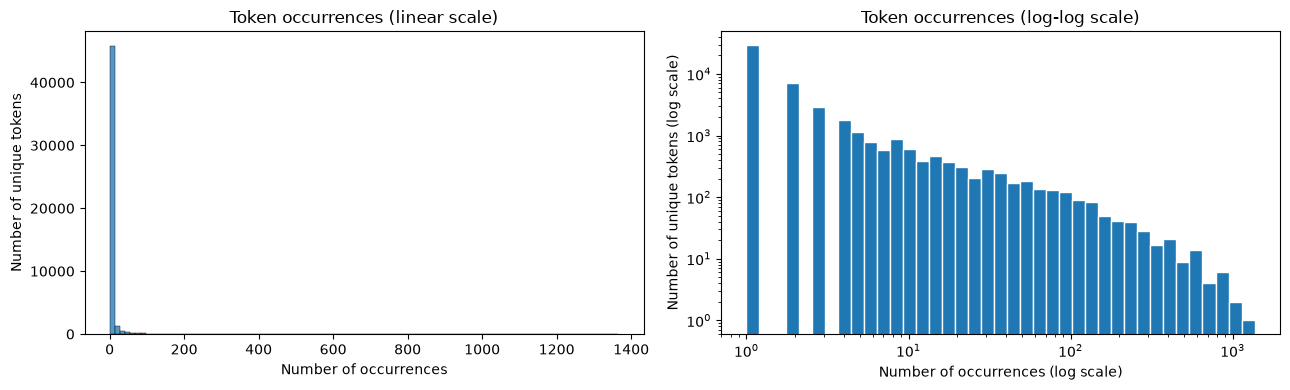

Overall phishing proportion: 0.3924
Training phishing proportion: 0.3924
Test phishing proportion: 0.3923
Train R^2: 0.7667
Test R^2: 0.6644
Largest absolute coefficients:
                  token      coef  abs_coef
740           localized  0.786698  0.786698
1504  background-image: -0.738467  0.738467
2362            thermal  0.703579  0.703579
1406         helvetica,  0.603340  0.603340
906               aging  0.577472  0.577472
2566         transcript  0.566564  0.566564
2559            april's -0.556519  0.556519
818                cnet -0.531785  0.531785
2532             xanaax  0.514832  0.514832
2365                rcs  0.511235  0.511235
1256             arial, -0.478029  0.478029
2657              zdnet -0.467907  0.467907
1619           warranty  0.459949  0.459949
2639            shopper -0.455355  0.455355
1511            burning -0.453470  0.453470
Largest positive coefficients:
           token      coef  abs_coef
740    localized  0.786698  0.786698
2362     thermal  0

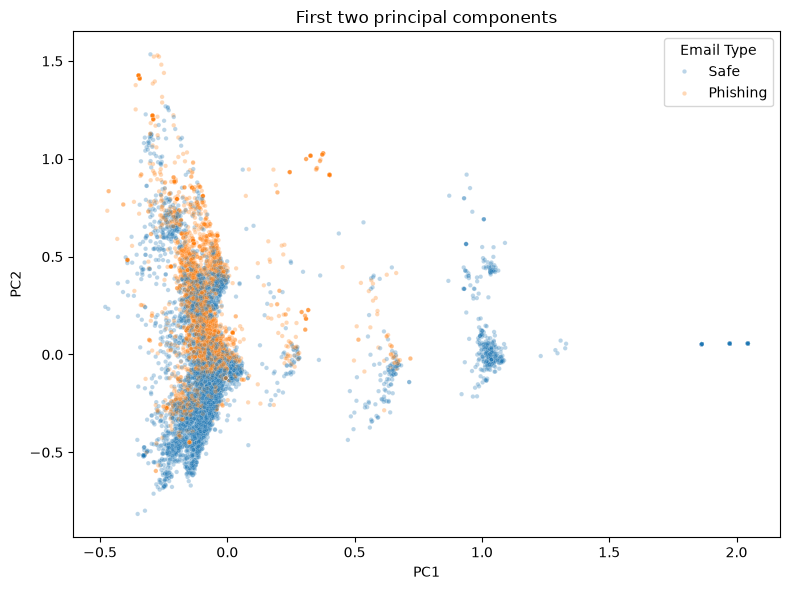

Maximum allowable components: 2711
PCA Train R^2: 0.7662
PCA Test R^2: 0.6649
Variance retained: 0.9999
Model comparison:
              Model  Train R^2  Test R^2  Train-Test Gap
Original regression     0.7667    0.6644          0.1022
     PCA regression     0.7662    0.6649          0.1013
Original train-test gap: 0.1022
PCA train-test gap: 0.1013
Change in test R^2: 0.0004


In [4]:
# Your Phase 2 solution to the problem goes here.

import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA

#Q1
#loads the token data and counts how often each token appears
with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
counts = pd.Series(token_count, dtype=int)

#prints summary stats on how often tokens appear
print('Unique tokens:', len(counts))
print('Share appearing exactly once:', round((counts == 1).mean(), 3))

#plots histograms on linear and log-log scales to compare distributions
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(counts, bins=100, ax=axes[0])
axes[0].set_title('Token occurrences (linear scale)')
axes[0].set_xlabel('Number of occurrences')
axes[0].set_ylabel('Number of unique tokens')

#uses logarithmic bins to better show the skewed distribution
log_bins = np.logspace(0, np.log10(counts.max()), 40)
axes[1].hist(counts, bins=log_bins, edgecolor='white')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_title('Token occurrences (log-log scale)')
axes[1].set_xlabel('Number of occurrences (log scale)')
axes[1].set_ylabel('Number of unique tokens (log scale)')

plt.tight_layout()
plt.show()

#Answer: The distribution is extremely right-skewed, with about 60% of tokens appearing only once while a few words appear hundreds of times. The log-log plot makes this long-tailed pattern easier to see.

#Q2
#loads the email data and separates the outcome from the token features
df = pd.read_parquet('data/Phishing_clean.parquet')
y = df['Email Type']
X = df.drop(columns='Email Type')

#performs an 80/20 split while preserving phishing and safe email proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=125, stratify=y
)

#checks that both datasets have similar class proportions
print('Overall phishing proportion:', round(y.mean(), 4))
print('Training phishing proportion:', round(y_train.mean(), 4))
print('Test phishing proportion:', round(y_test.mean(), 4))

#fits a linear regression on the original token features
lm = LinearRegression().fit(X_train, y_train)

train_r2 = lm.score(X_train, y_train)
test_r2 = lm.score(X_test, y_test)

print('Train R^2:', round(train_r2, 4))
print('Test R^2:', round(test_r2, 4))

#ranks tokens by their regression coefficients
coefs = pd.DataFrame({'token': X.columns, 'coef': lm.coef_})
coefs['abs_coef'] = coefs['coef'].abs()

print('Largest absolute coefficients:')
print(coefs.sort_values('abs_coef', ascending=False).head(15))

#separates positive and negative coefficients for easier interpretation
print('Largest positive coefficients:')
print(coefs.sort_values('coef', ascending=False).head(10))

print('Largest negative coefficients:')
print(coefs.sort_values('coef').head(10))

#Answer: The training and test R^2 values are printed above. Tokens with the largest absolute coefficients have the strongest influence on the linear predictions. Positive coefficients increase predicted phishing scores, while negative coefficients decrease them.

#Q3
#runs PCA with two components on the token matrix
pca2 = PCA(n_components=2)
Z2 = pca2.fit_transform(X)

#prints how much variance the first two components explain
print('PC1 explained variance:', round(pca2.explained_variance_ratio_[0], 4))
print('PC2 explained variance:', round(pca2.explained_variance_ratio_[1], 4))
print('Total explained variance:', round(pca2.explained_variance_ratio_.sum(), 4))

#builds a dataframe of the components labeled by email type
pc_df = pd.DataFrame(Z2, columns=['PC1', 'PC2'])
pc_df['Email Type'] = y.map({0: 'Safe', 1: 'Phishing'}).values

#plots the components with smaller markers and transparency
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=pc_df,
    x='PC1',
    y='PC2',
    hue='Email Type',
    alpha=0.3,
    s=10
)

plt.title('First two principal components')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend(title='Email Type')
plt.tight_layout()
plt.show()

#Answer: Phishing emails tend to sit higher on PC2, while safe emails spread out more along PC1. There is still substantial overlap, so the first two components do not clearly separate the classes.

#Q4
#checks that 2,610 components are allowed by the training data dimensions
n_components = 2610
max_components = min(X_train.shape)

print('Maximum allowable components:', max_components)

if n_components > max_components:
    raise ValueError(
        f'{n_components} components exceeds the maximum of {max_components}'
    )

#fits PCA only on training data to prevent data leakage
pca = PCA(n_components=n_components)
Z_train = pca.fit_transform(X_train)
Z_test = pca.transform(X_test)

#fits a linear regression on the principal components
lm_pc = LinearRegression().fit(Z_train, y_train)

pc_train_r2 = lm_pc.score(Z_train, y_train)
pc_test_r2 = lm_pc.score(Z_test, y_test)

print('PCA Train R^2:', round(pc_train_r2, 4))
print('PCA Test R^2:', round(pc_test_r2, 4))

#checks how much variance the selected components retain
print('Variance retained:', round(pca.explained_variance_ratio_.sum(), 4))

#compares the original regression against PCA regression
comparison = pd.DataFrame({
    'Model': ['Original regression', 'PCA regression'],
    'Train R^2': [train_r2, pc_train_r2],
    'Test R^2': [test_r2, pc_test_r2]
})

comparison['Train-Test Gap'] = (
    comparison['Train R^2'] - comparison['Test R^2']
)

print('Model comparison:')
print(comparison.round(4).to_string(index=False))

#Answer: The table compares both regressions using the same train-test split. The test R^2 measures performance on unseen data, while the train-test gap helps evaluate overfitting.

#Q5
#compares performance and checks whether PCA improved generalization
original_gap = train_r2 - test_r2
pca_gap = pc_train_r2 - pc_test_r2

print('Original train-test gap:', round(original_gap, 4))
print('PCA train-test gap:', round(pca_gap, 4))
print('Change in test R^2:', round(pc_test_r2 - test_r2, 4))

#Answer: PCA creates uncorrelated features, which can make high-dimensional regression easier to work with. It also allows us to reduce the number of features by keeping the components that explain the most variation. This can help reduce noise and overfitting, although keeping 2,610 components may give nearly the same performance as the original regression.



### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]
The AI generated code improves my original solution by making the calculations more efficient and the results easier to interpret. For the token frequency data, it removes unnecessary conversions and improves the histograms to better show the distribution. For the phishing data, it uses stratification to preserve class proportions and separates positive and negative coefficients for easier interpretation. For PCA, it adds explained variance ratios, improves the scatter plot, and checks that the number of components is valid. One limitation with the AI suggestions was that logarithmic bins were not necessarily better for every histogram, so I kept the original linear plot for comparison. I verified the final solution by running the code and checking the graphs, regression scores, and PCA outputs. The first two principal components explained only 1.97% of the variance. The original regression had a training R² of 0.7667 and a test R² of 0.6644, while PCA had a training R² of 0.7662 and a test R² of 0.6649. My main remaining concern is that PCA barely improves performance and does not significantly reduce overfitting.